در حال خواندن تصاویر به حافظه رم...
تمام شد! 100000 تصویر در رم ذخیره شد. حجم رم: 4915.2 MB


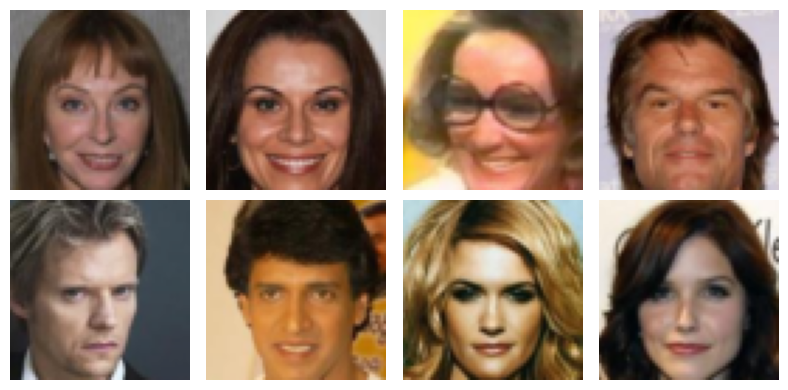

In [ ]:
import os
import torch
from PIL import Image
from torchvision import transforms
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt

IMAGE_DIR = "./img_align_celeba"
NUM_IMAGES = 100000  

transform = transforms.Compose([
    transforms.CenterCrop(140),
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

print("در حال خواندن تصاویر به حافظه رم...")
images_list = []

for i, filename in enumerate(os.listdir(IMAGE_DIR)):
    if filename.endswith(".jpg"):
        filepath = os.path.join(IMAGE_DIR, filename)
        img = Image.open(filepath).convert("RGB")
        images_list.append(transform(img))
        
        if len(images_list) >= NUM_IMAGES:
            break

all_images = torch.stack(images_list)
print(f"تمام شد! {len(all_images)} تصویر در رم ذخیره شد. حجم رم: {all_images.element_size() * all_images.nelement() / 1e6:.1f} MB")

dataset = TensorDataset(all_images)
dataloader = DataLoader(dataset, batch_size=64, shuffle=True , drop_last=True)

sample_batch = next(iter(dataloader))[0]
sample_batch = (sample_batch * 0.5 + 0.5).clamp(0, 1)

fig, axes = plt.subplots(2, 4, figsize=(8, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(sample_batch[i].permute(1, 2, 0).numpy())
    ax.axis("off")
plt.tight_layout()
plt.show()


In [77]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'

In [78]:
device

'cuda'

In [79]:
import torch.nn as nn

In [80]:
class Generator(nn.Module):
    def __init__(self , dim = 100):
        super().__init__()
 
        self.net = nn.Sequential(

            nn.ConvTranspose2d(in_channels= 100 ,
                         out_channels = 512 , 
                         kernel_size= 4, 
                         stride =  1 ,
                         padding = 0,
                         bias = False), 

            nn.BatchNorm2d(512),
            nn.ReLU(),


            nn.ConvTranspose2d(in_channels= 512 ,
                         out_channels = 256 , 
                         kernel_size=4 , 
                         stride =  2 ,
                         padding = 1,
                         bias = False), 

            nn.BatchNorm2d(256),
            nn.ReLU(),



            nn.ConvTranspose2d(in_channels= 256 ,
                         out_channels = 128 , 
                         kernel_size=4 , 
                         stride =  2 ,
                         padding = 1,
                         bias = False), 

            nn.BatchNorm2d(128),
            nn.ReLU(),


            nn.ConvTranspose2d(in_channels= 128 ,
                         out_channels = 32 , 
                         kernel_size=4 , 
                         stride =  2 ,
                         padding = 1,
                         bias = False), 

            nn.BatchNorm2d(32),
            nn.ReLU(),


            nn.ConvTranspose2d(in_channels= 32 ,
                         out_channels = 3 , 
                         kernel_size= 4 , 
                         stride =  2 ,
                         padding = 1),
            nn.Tanh()

        )

    def forward(self, x):
        return self.net(x)

    
G = Generator()
G.to(device)

Generator(
  (net): Sequential(
    (0): ConvTranspose2d(100, 512, kernel_size=(4, 4), stride=(1, 1), bias=False)
    (1): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): ConvTranspose2d(512, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (4): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
    (6): ConvTranspose2d(256, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (7): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (8): ReLU()
    (9): ConvTranspose2d(128, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (10): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (11): ReLU()
    (12): ConvTranspose2d(32, 3, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (13): Tanh()
  )
)

In [81]:
class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
 
        self.net = nn.Sequential(

            nn.Conv2d(in_channels= 3 ,
                         out_channels = 32 , 
                         kernel_size= 4, 
                         stride =  2 ,
                         padding = 1,
                         bias = False), 

            nn.LeakyReLU(0.2),


            nn.Conv2d(in_channels= 32 ,
                         out_channels = 64 , 
                         kernel_size=4 , 
                         stride =  2 ,
                         padding = 1,
                         bias = False), 

            nn.BatchNorm2d(64),
            nn.LeakyReLU(0.2),



            nn.Conv2d(in_channels= 64 ,
                         out_channels = 128 , 
                         kernel_size=4 , 
                         stride =  2 , 
                         padding = 1,
                         bias = False), 

            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2),


            nn.Conv2d(in_channels= 128 ,
                         out_channels = 256 , 
                         kernel_size=4 , 
                         stride =  2 ,
                         padding = 1,
                         bias = False), 

            nn.BatchNorm2d(256),
            nn.LeakyReLU(0.2),


            nn.Conv2d(in_channels= 256 ,
                         out_channels = 512 , 
                         kernel_size= 4 , 
                         stride =  1 ,
                         padding = 0)

        )

    def forward(self, x):
        return self.net(x)

    
D = Discriminator()
D.to(device)

Discriminator(
  (net): Sequential(
    (0): Conv2d(3, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (1): LeakyReLU(negative_slope=0.2)
    (2): Conv2d(32, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (3): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (4): LeakyReLU(negative_slope=0.2)
    (5): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (6): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (7): LeakyReLU(negative_slope=0.2)
    (8): Conv2d(128, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (9): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): LeakyReLU(negative_slope=0.2)
    (11): Conv2d(256, 512, kernel_size=(4, 4), stride=(1, 1))
  )
)

In [82]:

with torch.no_grad():
    def weights_init(module: nn.Module) -> None:
        if isinstance(module , (nn.Conv2d, nn.ConvTranspose2d)):
            nn.init.normal_(module.weight , mean= 0 , std = 0.02)

            if module.bias is not None:
                nn.init.constant_(module.bias, 0 )


        elif isinstance(module , (nn.BatchNorm2d)):
            nn.init.normal_(module.weight , mean= 0 , std = 0.02)

            if module.bias is not None:
                nn.init.constant_(module.bias, 0 )

In [83]:
G.apply(weights_init)
D.apply(weights_init)

Discriminator(
  (net): Sequential(
    (0): Conv2d(3, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (1): LeakyReLU(negative_slope=0.2)
    (2): Conv2d(32, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (3): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (4): LeakyReLU(negative_slope=0.2)
    (5): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (6): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (7): LeakyReLU(negative_slope=0.2)
    (8): Conv2d(128, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (9): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): LeakyReLU(negative_slope=0.2)
    (11): Conv2d(256, 512, kernel_size=(4, 4), stride=(1, 1))
  )
)

In [84]:
optimizerG = torch.optim.Adam(params = G.parameters(),
                            lr= 0.0002 ,
                            betas=(0.5, 0.999))

optimizerD = torch.optim.Adam(params = D.parameters(),
                            lr= 0.0002 ,
                            betas=(0.5, 0.999))

In [85]:
loss_fn = nn.BCEWithLogitsLoss()

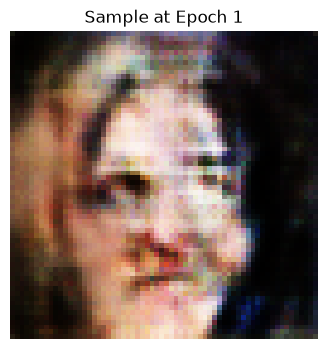

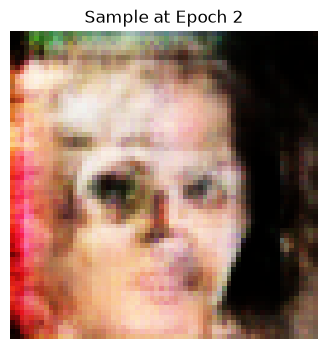

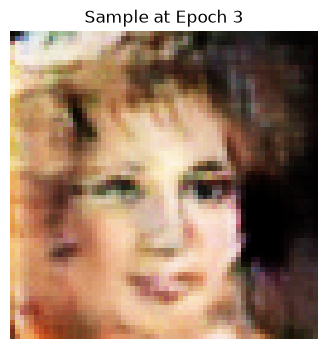

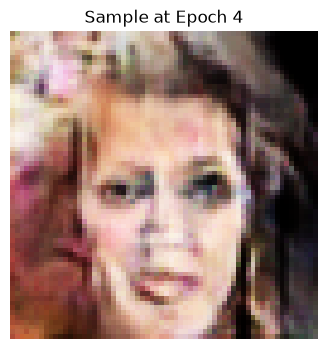

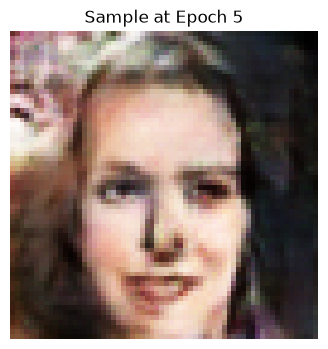

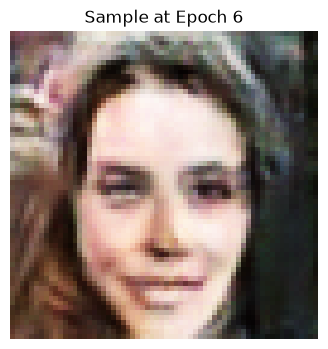

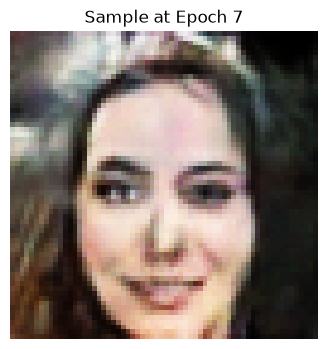

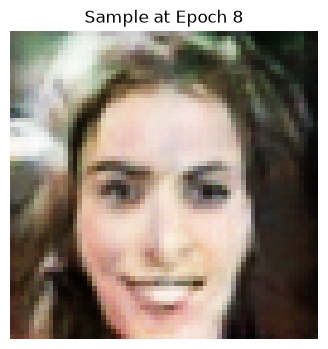

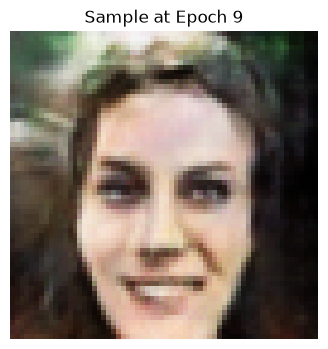

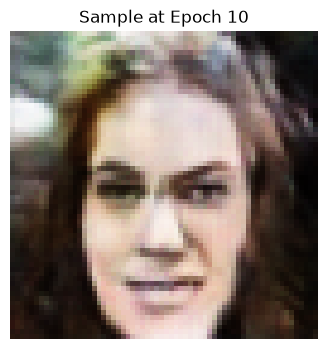

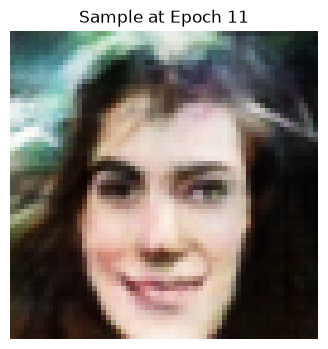

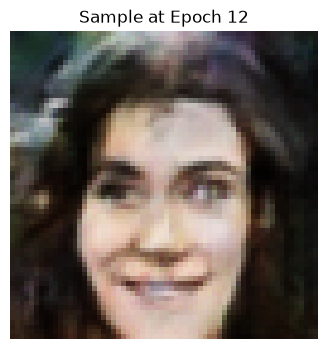

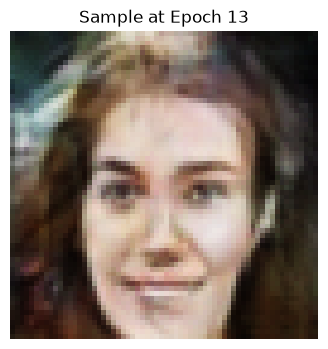

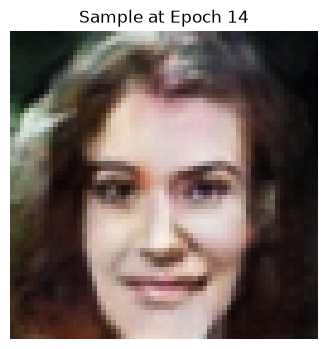

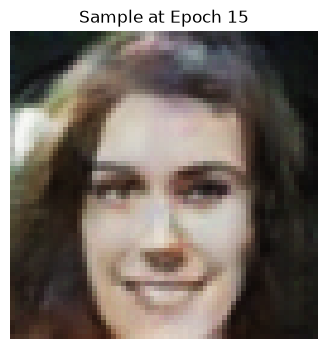

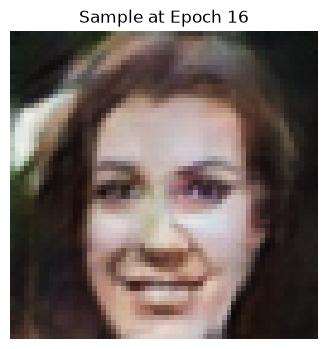

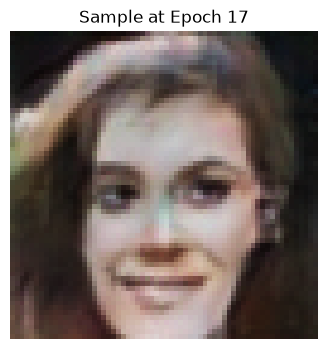

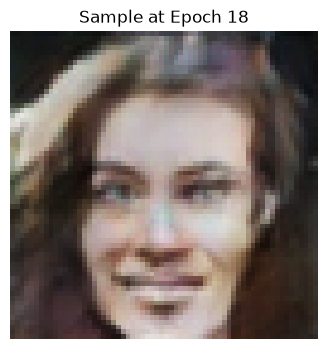

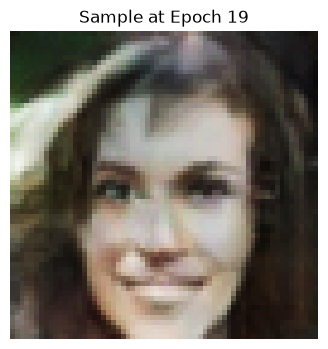

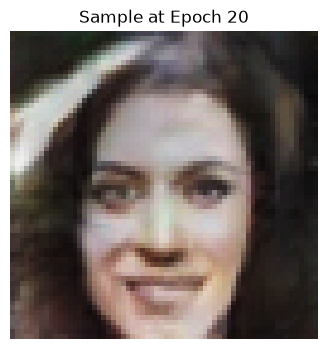

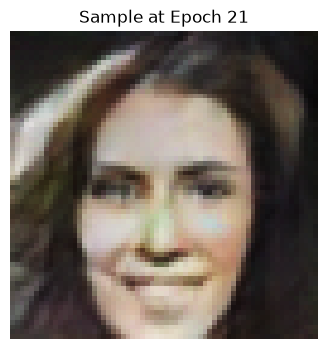

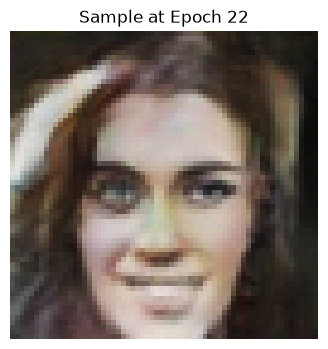

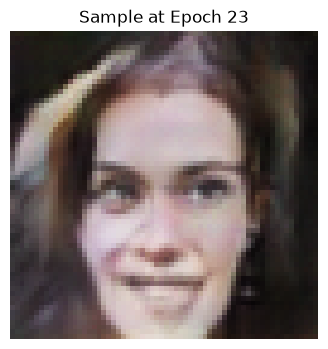

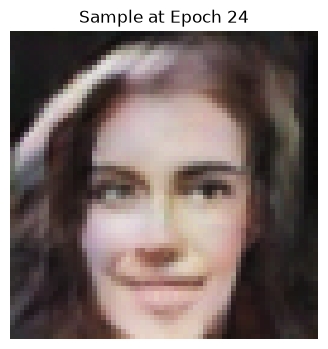

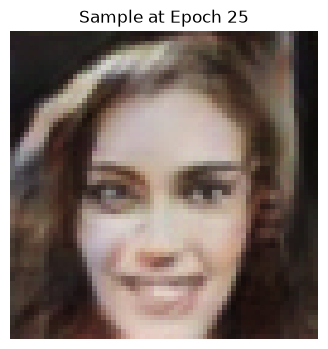

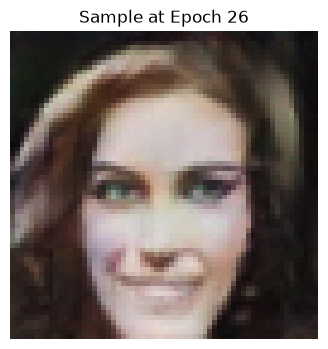

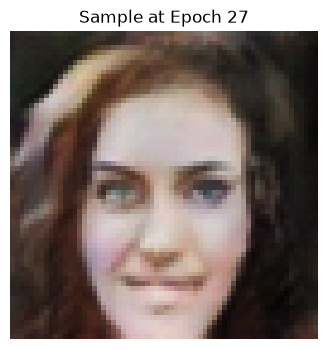

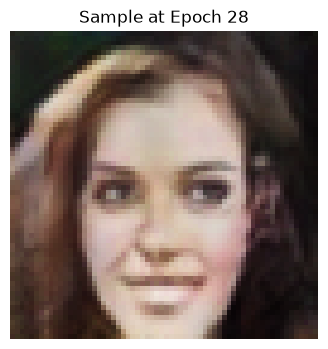

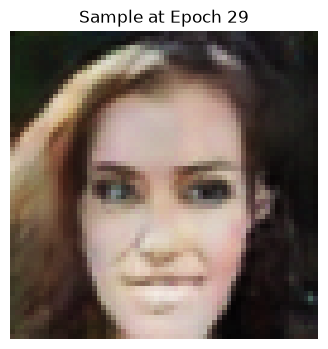

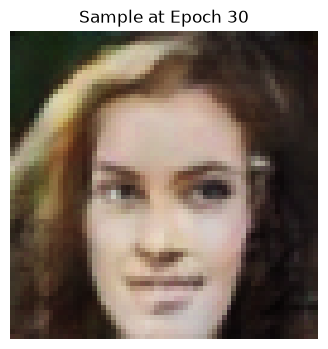

In [86]:
import matplotlib.pyplot as plt

fixed_noise = torch.randn(1, 100, 1, 1, device=device)

EPOCHS = 30

for epoch in range(EPOCHS):
    for real_images in dataloader:
        real_images = torch.stack(real_images).squeeze(0)
        real_images = real_images.to(device)
        b_size = real_images.size(0)

        optimizerD.zero_grad()

        pred_real = D(real_images)
        loss_real = loss_fn(pred_real, torch.full_like(pred_real, 0.9))

        z = torch.randn(b_size, 100, 1, 1, device=device)
        fake_images = G(z)
        pred_fake = D(fake_images.detach())
        loss_fake = loss_fn(pred_fake, torch.zeros_like(pred_fake))

        lossD = loss_real + loss_fake
        lossD.backward()
        optimizerD.step()

        optimizerG.zero_grad()
        pred_G = D(fake_images)
        lossG = loss_fn(pred_G, torch.ones_like(pred_G))
        lossG.backward()
        optimizerG.step()

    G.eval()
    with torch.no_grad():
        fake_sample = G(fixed_noise).detach().cpu().squeeze(0)
        fake_sample = (fake_sample + 1) / 2.0
        fake_sample = fake_sample.clamp(0, 1)

        img_to_show = fake_sample.permute(1, 2, 0).numpy()

        plt.figure(figsize=(4, 4))
        plt.axis("off")
        plt.title(f"Sample at Epoch {epoch + 1}")
        plt.imshow(img_to_show)
        plt.show()

    G.train()


In [122]:
G.eval()

num_samples = 300
latent_dim = 100

with torch.no_grad():
    z_pool = torch.randn(num_samples, latent_dim, 1, 1, device=device)
    fake_imgs = G(z_pool)
    fake_imgs = (fake_imgs * 0.5 + 0.5).clamp(0, 1)

In [ ]:
import matplotlib.pyplot as plt

num_to_show = 300
cols = 20
rows = num_to_show // cols  

fig, axes = plt.subplots(rows, cols, figsize=(40, 30))
axes = axes.flatten()

for i in range(num_to_show):
    img = fake_imgs[i].cpu().detach().permute(1, 2, 0).numpy()
    
    axes[i].imshow(img)
    axes[i].set_title(str(i), fontsize=8)
    axes[i].axis('off')

plt.show()


NameError: name 'fake_imgs' is not defined

Error in callback <function flush_figures at 0x00000283E68A4400> (for post_execute), with arguments args (),kwargs {}:


KeyboardInterrupt: 

In [126]:
man_glasses_idx = [21, 40, 69, 70, 88, 115, 169, 223, 252, 253, 277, 296]

man_no_glasses_idx = [17, 25, 37, 44, 53, 56, 57, 64, 67, 83, 84, 109, 140, 143, 155, 181, 186, 187, 192, 198, 202, 216, 259, 265, 274, 276, 293]

woman_no_glasses_idx = [2, 6, 7, 10, 23, 26, 31, 45, 47, 50, 59, 65, 68, 74, 81, 85, 87, 90, 91, 94, 97, 98, 100, 102, 107, 112, 116, 117, 118, 127, 130, 147, 150, 151, 154, 160, 166, 168, 175, 180, 188, 195, 201, 209, 210, 217, 218, 222, 224, 225, 231, 238, 241, 248, 258, 262, 268, 272, 279, 283, 288, 291, 298]


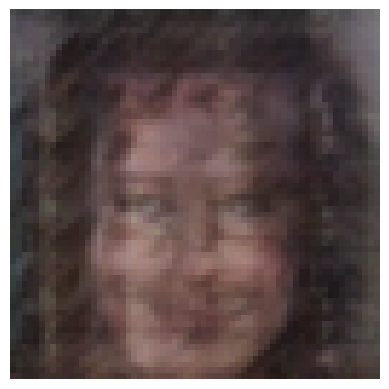

In [138]:
z_man_glasses = z_pool[man_glasses_idx].mean(dim=0, keepdim=True)
z_man_no_glasses = z_pool[man_no_glasses_idx].mean(dim=0, keepdim=True)
z_woman_no_glasses = z_pool[woman_no_glasses_idx].mean(dim=0, keepdim=True)

z_target = z_man_glasses - z_man_no_glasses + z_woman_no_glasses

with torch.no_grad():
    target_img = G(z_target)
    target_img = (target_img * 0.5 + 0.5).clamp(0, 1)

    img = target_img.squeeze(0).cpu().detach().permute(1, 2, 0).numpy()
    
    plt.imshow(img)
    plt.axis(False)
